# Hardware pilot: targeted interpretation scan

Exploratory follow-up to the [main pilot](hardware-pilot-261012.ipynb). Three independent reviews were screened; retain the channel-group explanation, estimator sensitivity and sampling-design check. All calculations below read the original r7 archives; no new extraction or package changes.

The [hybrid ER experiment](https://zenodo.org/records/17451096) measures 28 analogue Rössler-like oscillators with digitally implemented diffusive coupling. A setting is a fixed global gain control, indexed 0–700 at 0.005 V increments. Wiring and coupling form remain fixed within the sweep. We selected 29 settings: nine spanning the range, then 20 additional settings around the observed low-coupling change. Full 10 s records were anti-aliased from 50 kHz to 500 Hz (M=28, T=5,000); 5,000 was the smallest tested T passing every physical-fidelity audit. This is one selected sweep, not 29 independent experimental replicates.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from scipy.signal import hilbert
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/hardware_pilot/plot_hardware_pilot.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.empirical.hardware_pilot.plot_hardware_pilot import style, box, save
style()
RUN = ROOT/'results/hardware-pilot-261012/sweep29'
OUT = RUN.parent/'scan/retained'; OUT.mkdir(parents=True, exist_ok=True)
manifest = json.loads((RUN/'manifest.json').read_text())
steps = np.array([r['step'] for r in manifest['rows']])
voltage = steps*.005
I, J = np.triu_indices(28, 1)
SI = 'si_kernel_W-0.5_k-1'
needed = [SI, 'ids', 'dcorr_biased', 'si_gaussian_k-1', 'si_kozachenko_k-1']
matrices = {}
for row in manifest['rows']:
    path = next((RUN/'mpis').glob(f"*/????-{row['name']}/spi_mpis.npz"))
    with np.load(path) as bank: matrices[row['step']] = {k:bank[k] for k in needed}
def corr(a, b): return float(np.corrcoef(a, b)[0, 1])
def finish(fig, name):
    save(fig, OUT, name)
    display(Image(filename=str(OUT/f'{name}.png')))
phase, envelope = {}, {}
with np.load(RUN/'observations.npz') as bank:
    for step in (23, 24):
        x = bank[f'r17451096-s{step:03d}-t5000']
        analytic = hilbert(x-x.mean(axis=1, keepdims=True), axis=1)
        u = analytic/np.maximum(abs(analytic), 1e-12)
        c = u@u.conj().T/x.shape[1]
        phase[step] = abs(c)
        envelope[step] = np.corrcoef(abs(analytic))
mean_plv = {s:(phase[s].sum(axis=1)-np.diag(phase[s]))/27 for s in phase}
weak = np.flatnonzero(mean_plv[23] < .9)
core = ~np.isin(I, weak) & ~np.isin(J, weak)
print('Selected settings:', steps.tolist())
print('Less-coherent channels at setting 23 (1-based):', (weak+1).tolist())


Selected settings: [0, 7, 14, 16, 18, 19, 20, 21, 22, 23, 24, 26, 28, 35, 42, 49, 56, 63, 70, 77, 84, 87, 175, 262, 350, 437, 525, 612, 700]
Less-coherent channels at setting 23 (1-based): [12, 18, 21, 24]


## Retain: the global reversal localises to a small group

Four channels (12, 18, 21, 24; selected by mean incident Hilbert PLV < .9 at setting 23) account for much of the change. The 24-channel core already has negative SI×IDS agreement at 23 (−.816), remaining negative at 24 (−.897); all 28 channels give +.534→−.905. Single-channel deletion therefore missed a concentrated multi-channel contribution. Colours below follow the same dyads across recordings. This supports changing recruitment into coherent dynamics; it does not establish a change in the underlying coupling law. Channel selection is exploratory, and removing edges does not refit estimators.

A transparent corroboration is phase-locking × envelope-correlation agreement: .179→.992 across all dyads. The coherent-at-23 subset already gives .955. This describes the same recruitment contrast, not an independent mechanism. The waveform control below shows that its amplitude-coupling interpretation is not yet justified.

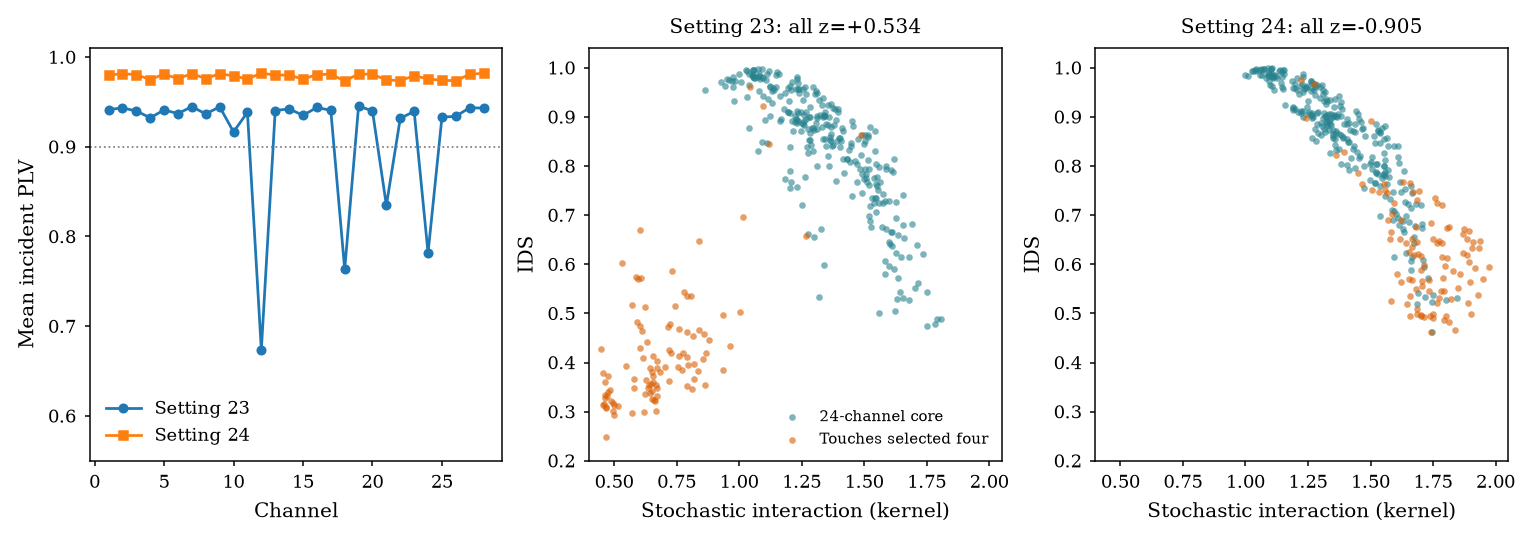

,setting,all_dyads,core_dyads,incident_dyads
0,23,0.534,-0.816,0.658
1,24,-0.905,-0.897,-0.624


,PLV_cutoff,dyads,z_23,z_24
0,0.900,281,-0.809,-0.896
1,0.925,280,-0.819,-0.896
2,0.950,252,-0.876,-0.900
3,0.975,139,-0.881,-0.889


,setting,all_dyads,coherent_at23
0,23,0.179,0.955
1,24,0.992,0.997


In [2]:
colors = ['#26828e', '#d95f02']
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0))
for step, marker in [(23, 'o'), (24, 's')]:
    axes[0].plot(np.arange(1,29), mean_plv[step], marker+'-', ms=3, label=f'Setting {step}')
axes[0].axhline(.9, color='.5', ls=':', lw=.7)
axes[0].set(xlabel='Channel', ylabel='Mean incident PLV', ylim=(.55, 1.01)); axes[0].legend(fontsize=7)
rows = []
for ax, step in zip(axes[1:], (23, 24)):
    x, y = matrices[step][SI][I,J], matrices[step]['ids'][I,J]
    for mask, color, label in [(core, colors[0], '24-channel core'), (~core, colors[1], 'Touches selected four')]:
        ax.scatter(x[mask], y[mask], s=7, color=color, alpha=.6, linewidths=0, label=label)
    ax.set(title=f'Setting {step}: all z={corr(x,y):+.3f}', xlabel='Stochastic interaction (kernel)', ylabel='IDS', xlim=(.4,2.05), ylim=(.2,1.04))
    rows.append(dict(setting=step, all_dyads=corr(x,y), core_dyads=corr(x[core],y[core]), incident_dyads=corr(x[~core],y[~core])))
axes[1].legend(fontsize=6, loc='lower right')
for ax in axes: box(ax)
finish(fig, 'phase-recruitment')
display(pd.DataFrame(rows).round(3))
# Freeze edge groups at setting 23; vary only the phase-locking cutoff.
checks=[]
for threshold in (.90,.925,.95,.975):
    mask=phase[23][I,J]>threshold
    checks.append(dict(PLV_cutoff=threshold, dyads=int(mask.sum()), **{f'z_{s}':corr(matrices[s][SI][I,J][mask], matrices[s]['ids'][I,J][mask]) for s in (23,24)}))
display(pd.DataFrame(checks).round(3))
assert weak.tolist()==[11,17,20,23]
assert all(r['z_23'] < 0 and r['z_24'] < 0 for r in checks)

locked23 = phase[23][I,J] > .95
phase_envelope = [dict(setting=s, all_dyads=corr(phase[s][I,J], envelope[s][I,J]),
    coherent_at23=corr(phase[s][I,J][locked23], envelope[s][I,J][locked23])) for s in (23,24)]
display(pd.DataFrame(phase_envelope).round(3))


## Retain: estimator agreement is itself informative

The positive SI×IDS agreement weakens for all three SI estimators, but only the kernel estimate strongly reverses. IDS ordering across dyads is largely preserved between 23 and 24; kernel-SI ordering is reorganised. The descriptor identifies where statistical lenses cease agreeing, but cannot yet be named a general temporal-coupling axis. Stochastic interaction combines bidirectional one-step transfer terms and instantaneous conditional dependence, rather than pure causal flow ([Oizumi et al., 2016](https://doi.org/10.1371/journal.pcbi.1004654)).

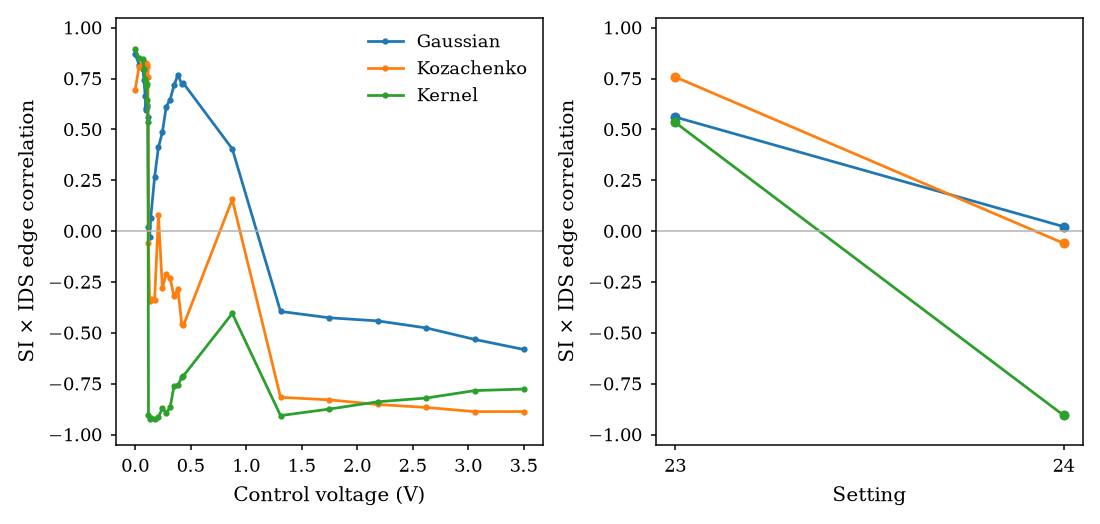

,estimator,z23,z24
0,Gaussian,0.561,0.022
1,Kozachenko,0.758,-0.060
2,Kernel,0.534,-0.905


In [3]:
estimators = [('si_gaussian_k-1','Gaussian'), ('si_kozachenko_k-1','Kozachenko'), (SI,'Kernel')]
fig, axes = plt.subplots(1, 2, figsize=(6.0, 3.0))
values=[]
for k,label in estimators:
    z=np.array([corr(matrices[s][k][I,J], matrices[s]['ids'][I,J]) for s in steps])
    axes[0].plot(voltage, z, '.-', ms=3, label=label)
    axes[1].plot([23,24], z[np.isin(steps,[23,24])], 'o-', label=label)
    values.append(dict(estimator=label,z23=float(z[steps==23][0]),z24=float(z[steps==24][0])))
axes[0].set(xlabel='Control voltage (V)',ylabel='SI × IDS edge correlation',ylim=(-1.05,1.05))
axes[1].set(xlabel='Setting',ylabel='SI × IDS edge correlation',xticks=[23,24],ylim=(-1.05,1.05))
axes[0].legend(fontsize=7)
for ax in axes: ax.axhline(0,color='.7',lw=.6); box(ax)
finish(fig, 'estimator-sensitivity')
display(pd.DataFrame(values).round(3))


## Retain as scope control: PCA depends on the sampled control range

The pilot deliberately oversamples the low-coupling change. Interval weights below redistribute variance toward the wider high-coupling intervals; they are a sensitivity check, not a privileged correction or independent validation. Their leading coordinate follows the original PC2 more than PC1. The local 23→24 feature contrast does not depend on PCA fitting. Later PC2 reversals were not promoted as a separate mechanism: their underlying edge profiles approach near-constant values under strong synchronisation.

In [4]:
with np.load(RUN/'analysis/features.npz') as bank:
    z=bank['z'][:,bank['selected']].astype(float)
    original=bank['scores']
def fit_weights(weights):
    weights=weights/weights.sum()
    center=weights@z
    _,singular,v=np.linalg.svd((z-center)*np.sqrt(weights[:,None]),full_matrices=False)
    score=(z-center)@v[0]
    return score,float(singular[0]**2/sum(singular**2))
gaps=np.diff(voltage)
interval_weights=np.r_[gaps[0]/2, (gaps[:-1]+gaps[1:])/2,gaps[-1]/2]
weight_checks=[]
for label,weights in [('Equal records (all29)',np.ones(len(z))),('Control-interval weights',interval_weights)]:
    score,variance=fit_weights(weights)
    weight_checks.append(dict(fit=label,PC1_variance=variance,abs_r_original_PC1=abs(corr(score,original[:,0])),abs_r_original_PC2=abs(corr(score,original[:,1]))))
display(pd.DataFrame(weight_checks).round(3))
(OUT/'retained-summary.json').write_text(json.dumps(dict(weak_channels_1based=(weak+1).tolist(),edge_group_contrasts=rows,phase_envelope=phase_envelope,phase_threshold_sensitivity=checks,estimator_contrasts=values,pca_weighting=weight_checks),indent=2)+'\n')


,fit,PC1_variance,abs_r_original_PC1,abs_r_original_PC2
0,Equal records (all29),0.451,1.000,0.048
1,Control-interval weights,0.486,0.135,0.979


1990

## Character-axis naming: separate estimator and lag contrasts

The leading loading compares Pearson at 2 ms with Kendall at 20 ms: both estimator and lag differ. Same-lag Pearson–Spearman profiles remain almost identical here, while same-estimator, different-lag agreement varies substantially. The defensible label is **lag-profile agreement**, not a calibrated monotonic-nonlinearity or propagation-delay axis. Positive z means an approximately positive affine relationship between the two edge profiles; it does not establish that the raw channel relationship is linear. The full-record phase/envelope contrast repeats in both five-second halves, a within-record sensitivity check rather than replication.

In [5]:
pairs = [
    ('cov_EmpiricalCovariance','spearmanr','Instantaneous Pearson–Spearman'),
    ('corr_pearson_tau-1','corr_spearman_tau-1','Pearson–Spearman, both 2 ms'),
    ('corr_pearson_tau-1','corr_pearson_tau-10','Pearson, 2 vs 20 ms'),
    ('corr_pearson_tau-1','corr_kendall_tau-10','Leading PC1 feature')]
records=[]
for row in manifest['rows']:
    path=next((RUN/'mpis').glob(f"*/????-{row['name']}/spi_mpis.npz"))
    with np.load(path) as bank:
        for a,b,label in pairs: records.append(dict(step=row['step'],feature=label,z=corr(bank[a][I,J],bank[b][I,J])))
lag_table=pd.DataFrame(records)
display(lag_table[lag_table.step.isin([0,23,24,87,350])].pivot(index='feature',columns='step',values='z').round(3))
lag_table.to_csv(OUT/'matched-lag-contrasts.csv',index=False)
def phase_envelope_diagnostic(x, trim=0):
    h=hilbert(x-x.mean(axis=1,keepdims=True),axis=1)
    if trim: h=h[:,trim:-trim]
    amp=abs(h);u=h/np.maximum(amp,1e-12)
    plv=abs(u@u.conj().T/h.shape[1])[I,J];env=np.corrcoef(amp)[I,J]
    z=corr(plv,env) if plv.std()>1e-8 and env.std()>1e-8 else np.nan
    return dict(z=z,mean_PLV=float(plv.mean()),sd_PLV=float(plv.std()),
        amplitude_cv_median=float(np.median(amp.std(axis=1)/amp.mean(axis=1))))
halves=[]
with np.load(RUN/'observations.npz') as bank:
    for step in [21,22,23,24,26,28]:
        x=bank[f'r17451096-s{step:03d}-t5000']
        halves.append(dict(step=step,full=phase_envelope_diagnostic(x)['z'],
            first_half=phase_envelope_diagnostic(x[:,:2500])['z'],second_half=phase_envelope_diagnostic(x[:,2500:])['z']))
display(pd.DataFrame(halves).round(3))
pd.DataFrame(halves).to_csv(OUT/'within-record-halves.csv',index=False)


step,0,23,24,87,350
feature,,,,,
Instantaneous Pearson–Spearman,1.000,1.000,1.000,0.998,1.000
Leading PC1 feature,-0.956,-0.553,-0.385,0.950,0.976
"Pearson, 2 vs 20 ms",-0.959,-0.665,-0.559,0.882,0.921
"Pearson–Spearman, both 2 ms",1.000,1.000,0.999,0.999,0.999


,step,full,first_half,second_half
0,21,0.060,0.066,0.056
1,22,0.130,0.151,0.115
2,23,0.179,0.207,0.158
3,24,0.992,0.992,0.992
4,26,0.993,0.993,0.993
5,28,0.991,0.991,0.991


## Material qualification: broadband Hilbert agreement is waveform-sensitive

All checks below use the same central nine seconds (0.5 s trimmed at each end). A fourth-order zero-phase bandpass around the ~116 Hz carrier preserves the high coherence at 24 but reduces phase/envelope z from .992 to .19–.38; the envelope coefficient of variation also contracts sharply. These bands change the estimand; this alone does not prove the broadband result is an artifact. However, the explicit fixed-waveform counterexample below produces z>.999 without any separate amplitude process: every channel is merely a phase-shifted copy of cos(θ)+0.3cos(2θ). Thus the broadband axis cannot yet be named correspondence between distinct phase and amplitude coupling mechanisms. This is a semantic calibration failure, not an invalid numerical descriptor. Waveform-shape confounding of Hilbert-derived coupling has established precedents, although [Lozano-Soldevilla et al.](https://doi.org/10.3389/fncom.2016.00087) study a different coupling statistic.

The best current physical interpretation remains recruitment into phase-coherent dynamics. Prioritise a frozen, waveform-controlled feature panel and its transfer to the companion topology before claiming a general mechanistic axis.

,step,band,z,mean_PLV,sd_PLV,amplitude_cv_median
8,23,Broadband,0.1759,0.9124,0.1106,0.2104
9,23,80–160 Hz,0.0939,0.9314,0.1113,0.0426
10,23,90–140 Hz,0.1225,0.9316,0.1113,0.0142
11,23,100–130 Hz,0.2227,0.9317,0.1113,0.0060
12,24,Broadband,0.9923,0.9785,0.0185,0.2136
13,24,80–160 Hz,0.3802,0.9995,0.0003,0.0395
14,24,90–140 Hz,0.2054,0.9997,0.0002,0.0121
15,24,100–130 Hz,0.1950,0.9998,0.0002,0.0025


,harmonic_amplitude,z,mean_PLV,sd_PLV,amplitude_cv_median
0,0.0,NaN,1.00000,0.00000,0.00000
1,0.1,1.00000,0.99838,0.00170,0.07047
2,0.2,0.99997,0.99341,0.00686,0.13949
3,0.3,0.99986,0.98474,0.01569,0.20565
4,0.4,0.99951,0.97179,0.02845,0.26763


Pure sine: profile variance is numerical zero, so z is undefined.


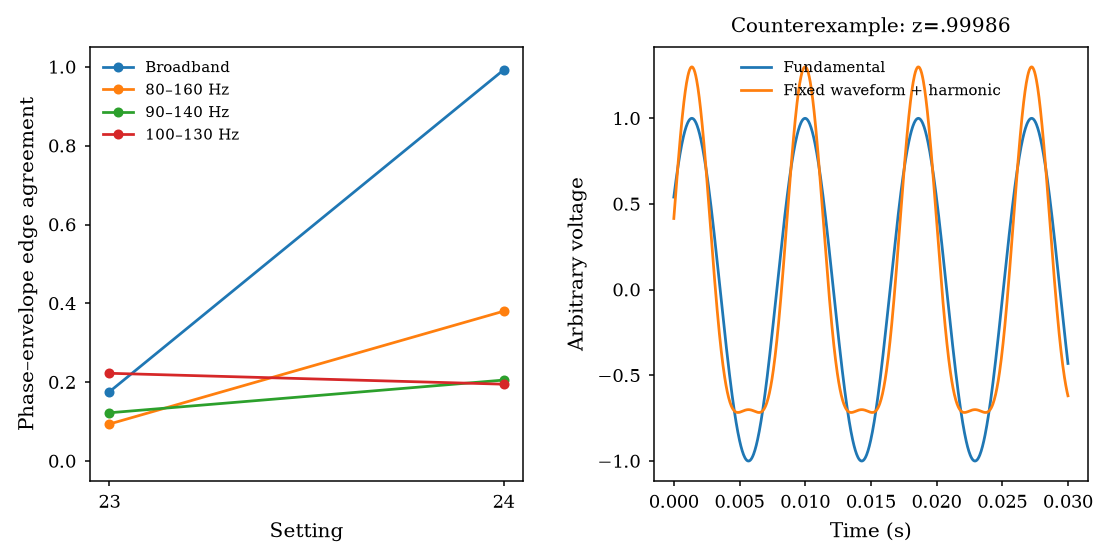

In [6]:
from scipy.signal import butter, sosfiltfilt
bands=[None,(80,160),(90,140),(100,130)]
filtered=[]
with np.load(RUN/'observations.npz') as bank:
    for step in [21,22,23,24,26,28,87]:
        x=bank[f'r17451096-s{step:03d}-t5000']
        for band in bands:
            y=x if band is None else sosfiltfilt(butter(4,band,btype='band',fs=500,output='sos'),x,axis=1)
            filtered.append(dict(step=step,band='Broadband' if band is None else f'{band[0]}–{band[1]} Hz',**phase_envelope_diagnostic(y,trim=250)))
filtered=pd.DataFrame(filtered)
display(filtered[filtered.step.isin([23,24])].round(4))
filtered.to_csv(OUT/'carrier-band-sensitivity.csv',index=False)
time=np.arange(5000)/500
angle=2*np.pi*116*time+np.linspace(-1,1,28)[:,None]
toy=[]
for harmonic in [0,.1,.2,.3,.4]:
    toy.append(dict(harmonic_amplitude=harmonic,**phase_envelope_diagnostic(np.cos(angle)+harmonic*np.cos(2*angle))))
toy=pd.DataFrame(toy)
display(toy.round(5))
print('Pure sine: profile variance is numerical zero, so z is undefined.')
toy.to_csv(OUT/'fixed-waveform-counterexample.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(6.2,3.0))
for label,g in filtered[filtered.step.isin([23,24])].groupby('band',sort=False):
    axes[0].plot(g.step,g.z,'o-',label=label)
axes[0].set(xlabel='Setting',ylabel='Phase–envelope edge agreement',xticks=[23,24],ylim=(-.05,1.05));axes[0].legend(fontsize=6)
fine_time=np.linspace(0,.03,900); fine_angle=2*np.pi*116*fine_time-1
axes[1].plot(fine_time,np.cos(fine_angle),label='Fundamental')
axes[1].plot(fine_time,np.cos(fine_angle)+.3*np.cos(2*fine_angle),label='Fixed waveform + harmonic')
axes[1].set(xlabel='Time (s)',ylabel='Arbitrary voltage',title='Counterexample: z=.99986');axes[1].legend(fontsize=6)
for ax in axes: box(ax)
finish(fig,'waveform-calibration')
